# 18. Analysing experiments with SQL

**Goal and requirements.** Write several experiments to an SQLite database with `ExperimentStore` and analyse the results with queries: champions, error by family, selection decisions, cost, error per origin and external evaluation. Two offline series (one with structure, one pure noise) in protocols A and B give four runs. `stats` and `plot` extras; no download.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt

import autohybts
from autohybts import AutoHybridExperiment, ExperimentStore
from autohybts.datasets import get_data

warnings.filterwarnings("ignore")
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc3


## 1. Data and protocol

`synthetic_daily` has a trend, a weekly cycle and AR(1) noise, structure a residual corrector can use; `white_noise_daily` is a level plus white noise, where nothing beyond the mean is predictable. Each series runs in protocols A (7 steps at once) and B (one step at a time), with the same small search space.

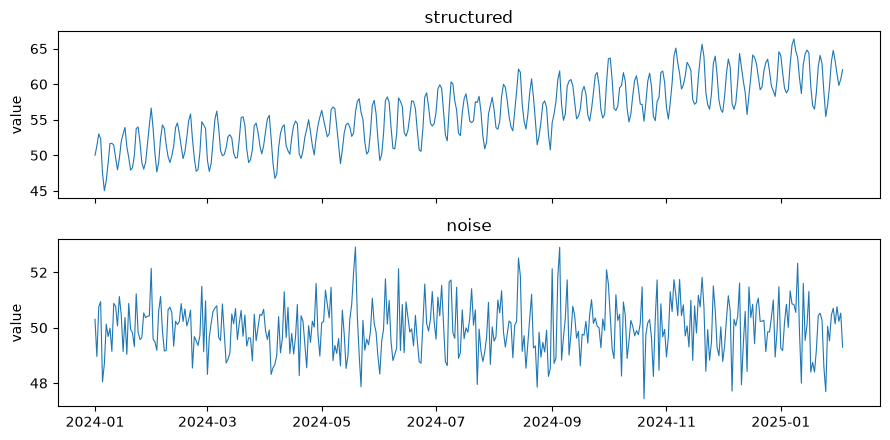

In [2]:
SERIES = {
    "structured": get_data("synthetic_daily", n=400),
    "noise": get_data("white_noise_daily", n=400),
}
SETTINGS = {
    "fh": 7,
    "session_id": 42,
    "budget": "smoke",
    "base_models": ["naive", "seasonal_naive", "linear", "knn", "exponential_smoothing"],
    "correctors": ["linear", "knn"],
}
fig, axes = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
for ax, (name, y) in zip(axes, SERIES.items(), strict=True):
    ax.plot(y.index, y.to_numpy(), linewidth=0.8)
    ax.set(title=name, ylabel="value")
fig.tight_layout()
plt.show()

## 2. Logging the experiments

The database lives in `artifacts/`, out of git, and is recreated on every run of the notebook. Each experiment is compared, finalized, evaluated once on the sealed test and logged with tags; `values=True` also writes the test forecasts and observations, used in section 4.

In [3]:
path = Path("artifacts/experiments.db")
path.unlink(missing_ok=True)
store = ExperimentStore(path)

for name, y in SERIES.items():
    for variant in ("A", "B"):
        exp = AutoHybridExperiment(variant=variant, **SETTINGS).fit(y)
        best = exp.compare_models().best
        final = exp.finalize_model(best)
        exp.evaluate_external(final)
        store.log(
            exp,
            name=f"{name}-{variant}",
            tags={"series": name, "protocol": variant},
            models=[final],
            values=True,
        )
store.runs()[["name", "variant", "n_origins", "ranking_metric", "champion_label"]]

,name,variant,n_origins,ranking_metric,champion_label
0,noise-B,B,14,MASE,exponential_smoothing(season_length=7)
1,noise-A,A,14,MASE,exponential_smoothing(season_length=7)
2,structured-B,B,14,MASE,exponential_smoothing(season_length=7) + linea...
3,structured-A,A,14,MASE,exponential_smoothing(season_length=7)


In [4]:
store.query(
    """
    SELECT name AS table_name FROM sqlite_master WHERE type = 'table' ORDER BY name
    """
)

,table_name
0,candidates
1,decisions
2,evaluations
3,events
4,external
5,ledger
6,meta
7,metrics
8,models
9,predictions


## 3. Queries

### Champions and leaderboard

For each run, the champion, its mean error in the selection layer and how many candidates the search evaluated.

In [5]:
store.query(
    """
    SELECT r.name,
           r.champion_label AS champion,
           ROUND(m.value, 3) AS select_mase,
           (SELECT COUNT(*) FROM ledger l
             WHERE l.run_id = r.run_id AND l.status = 'EVALUATED') AS evaluated
    FROM runs r
    JOIN metrics m
      ON m.run_id = r.run_id AND m.candidate_id = r.champion_id
     AND m.layer = 'select' AND m.metric = r.ranking_metric
    ORDER BY r.name
    """
)

,name,champion,select_mase,evaluated
0,noise-A,exponential_smoothing(season_length=7),0.865,9
1,noise-B,exponential_smoothing(season_length=7),0.865,9
2,structured-A,exponential_smoothing(season_length=7),0.790,9
3,structured-B,exponential_smoothing(season_length=7) + linea...,0.652,9


In [6]:
run_id = store.query("SELECT run_id FROM runs WHERE name = ?", ("structured-A",)).run_id[0]
store.query(
    """
    SELECT c.label, c.family, ROUND(m.value, 3) AS mase, e.coverage, e.is_champion
    FROM metrics m
    JOIN candidates c USING (run_id, candidate_id)
    JOIN evaluations e USING (run_id, candidate_id, layer)
    WHERE m.run_id = ? AND m.layer = 'select' AND m.metric = 'MASE'
    ORDER BY mase
    """,
    (run_id,),
)

,label,family,mase,coverage,is_champion
0,exponential_smoothing(season_length=7),statistical,0.790,1.0,1
1,exponential_smoothing(season_length=7) + linea...,residual,0.794,1.0,0
2,knn(lags=7),kernel,0.969,1.0,0
3,linear(lags=7),linear,0.987,1.0,0


### Error by family

Mean error of each family in the search layer, per run. The query aggregates in SQL and pandas only pivots the table for the plot.

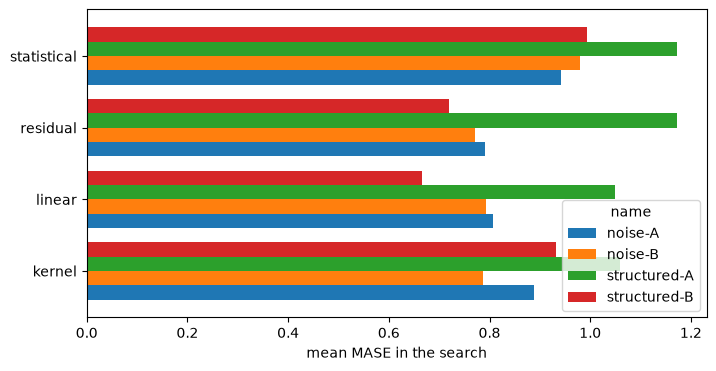

name,noise-A,noise-B,structured-A,structured-B
family,,,,
kernel,0.889,0.787,1.059,0.931
linear,0.806,0.794,1.049,0.666
residual,0.791,0.772,1.173,0.720
statistical,0.941,0.980,1.173,0.994


In [7]:
families = store.query(
    """
    SELECT r.name, c.family, AVG(m.value) AS mase, COUNT(*) AS candidates
    FROM metrics m
    JOIN candidates c USING (run_id, candidate_id)
    JOIN runs r USING (run_id)
    WHERE m.layer = 'search' AND m.metric = 'MASE'
    GROUP BY r.name, c.family
    """
)
table = families.pivot(index="family", columns="name", values="mase")
ax = table.plot.barh(figsize=(8, 4), width=0.8)
ax.set(xlabel="mean MASE in the search", ylabel="")
plt.show()
table.round(3)

### Selection decisions

Each challenger compared with the current champion: accepted or rejected, and why. On the noise series a corrector should not be accepted; when it is, the median gain and the win rate show by how little.

In [8]:
store.query(
    """
    SELECT r.name, d.family, d.challenger_label AS challenger, d.accepted AS accepted,
           ROUND(d.median_gain, 3) AS median_gain, ROUND(d.win_rate, 2) AS win_rate,
           d.reason_codes AS reasons
    FROM decisions d JOIN runs r USING (run_id)
    ORDER BY r.name, d.step
    """
)

,name,family,challenger,accepted,median_gain,win_rate,reasons
0,noise-A,linear,linear(lags=7),0,-0.025,0.43,"[""median_gain_below_threshold"", ""win_rate_belo..."
1,noise-A,kernel,knn(lags=7),0,-0.040,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."
2,noise-A,residual,exponential_smoothing(season_length=7) + linea...,0,0.015,0.57,"[""median_gain_below_threshold"", ""win_rate_belo..."
3,noise-B,linear,linear(lags=7),0,-0.055,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."
4,noise-B,kernel,knn(lags=7),0,-0.051,0.43,"[""median_gain_below_threshold"", ""win_rate_belo..."
5,noise-B,residual,exponential_smoothing(season_length=7) + linea...,0,0.012,0.57,"[""median_gain_below_threshold"", ""win_rate_belo..."
6,structured-A,linear,linear(lags=7),0,-0.061,0.43,"[""median_gain_below_threshold"", ""win_rate_belo..."
7,structured-A,kernel,knn(lags=7),0,-0.424,0.43,"[""median_gain_below_threshold"", ""win_rate_belo..."
8,structured-A,residual,exponential_smoothing(season_length=7) + linea...,0,0.003,0.57,"[""median_gain_below_threshold"", ""win_rate_belo..."
9,structured-B,linear,linear(lags=7),0,-0.076,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."


In [9]:
store.query(
    """
    SELECT reason_codes AS reason, COUNT(*) AS n
    FROM decisions WHERE accepted = 0
    GROUP BY reason_codes ORDER BY n DESC
    """
)

,reason,n
0,"[""median_gain_below_threshold"", ""win_rate_belo...",11


### Cost and error

Fit time summed over the origins against the search error, one mark per candidate. More cost does not guarantee less error.

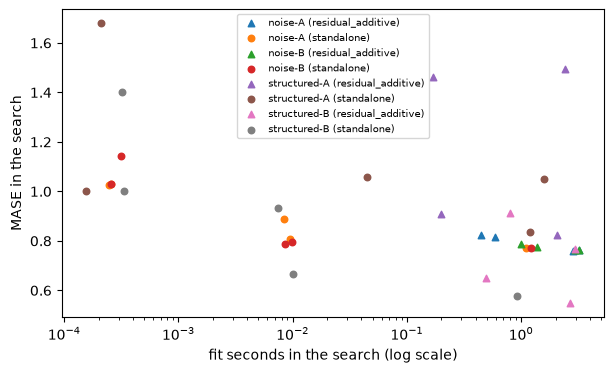

In [10]:
cost = store.query(
    """
    SELECT r.name, c.label, c.strategy, SUM(t.fit_seconds) AS seconds, m.value AS mase
    FROM trials t
    JOIN candidates c USING (run_id, candidate_id)
    JOIN runs r USING (run_id)
    JOIN metrics m
      ON m.run_id = t.run_id AND m.candidate_id = t.candidate_id
     AND m.layer = 'search' AND m.metric = 'MASE'
    WHERE t.layer = 'search'
    GROUP BY t.run_id, t.candidate_id
    """
)
fig, ax = plt.subplots(figsize=(7, 4))
for (name, strategy), part in cost.groupby(["name", "strategy"]):
    ax.scatter(
        part.seconds,
        part.mase,
        s=22,
        marker="o" if strategy == "standalone" else "^",
        label=f"{name} ({strategy})",
    )
ax.set(xscale="log", xlabel="fit seconds in the search (log scale)", ylabel="MASE in the search")
ax.legend(fontsize=7)
plt.show()

### Error per origin

The metrics of each origin are in `trial_metrics`. Here, the champion against persistence at each origin of the selection layer: is the champion's gain consistent or does it depend on a few origins?

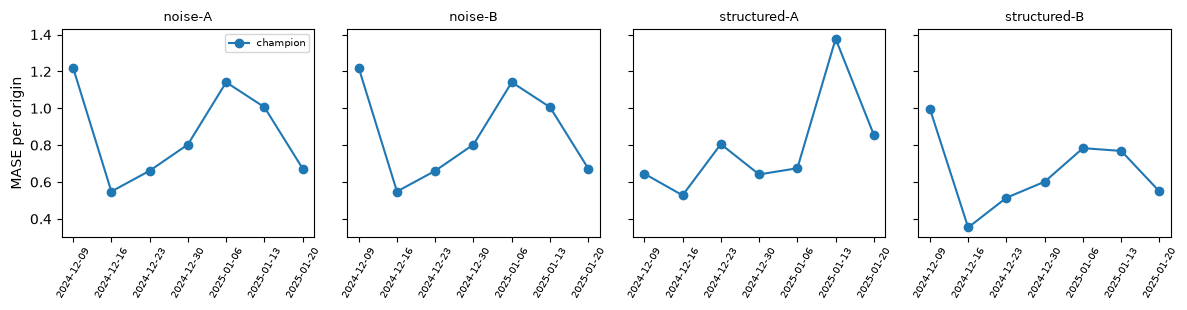

In [11]:
origins = store.query(
    """
    SELECT r.name, t.origin, c.label, tm.value AS mase,
           t.candidate_id = r.champion_id AS champion
    FROM trial_metrics tm
    JOIN trials t USING (run_id, candidate_id, unit_id)
    JOIN candidates c USING (run_id, candidate_id)
    JOIN runs r USING (run_id)
    WHERE t.layer = 'select' AND tm.metric = 'MASE'
      AND (t.candidate_id = r.champion_id OR c.label = 'naive')
    ORDER BY r.name, t.origin
    """
)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, (name, part) in zip(axes, origins.groupby("name"), strict=True):
    for is_champion, rows in part.groupby("champion"):
        ax.plot(
            rows.origin.str[:10],
            rows.mase,
            marker="o",
            label="champion" if is_champion else "naive",
        )
    ax.set_title(name, fontsize=9)
    ax.tick_params(axis="x", rotation=60, labelsize=7)
axes[0].set_ylabel("MASE per origin")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## 4. External evaluation

The champion's error in the selection against its error on the sealed test. A large difference means the validation was optimistic; the database makes it possible to follow this over many runs.

In [12]:
store.query(
    """
    SELECT r.name,
           ROUND(m.value, 3) AS select_mase,
           ROUND(x.value, 3) AS test_mase,
           ROUND(x.value - m.value, 3) AS difference
    FROM runs r
    JOIN metrics m
      ON m.run_id = r.run_id AND m.candidate_id = r.champion_id
     AND m.layer = 'select' AND m.metric = 'MASE'
    JOIN models mo ON mo.run_id = r.run_id
    JOIN external x
      ON x.run_id = r.run_id AND x.model_id = mo.model_id AND x.metric = 'MASE'
    ORDER BY r.name
    """
)

,name,select_mase,test_mase,difference
0,noise-A,0.865,0.502,-0.362
1,noise-B,0.865,0.502,-0.362
2,structured-A,0.790,1.627,0.838
3,structured-B,0.652,0.552,-0.101


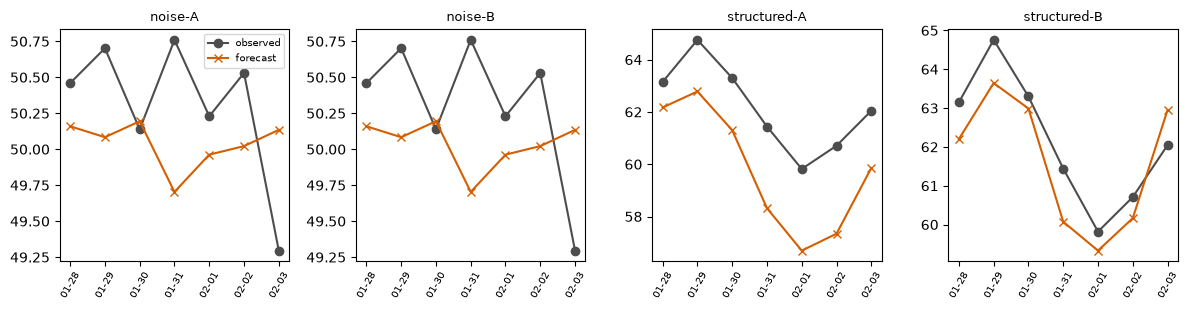

In [13]:
forecasts = store.query(
    """
    SELECT r.name, p.timestamp, p.y_pred, p.y_true
    FROM predictions p JOIN runs r USING (run_id)
    ORDER BY r.name, p.timestamp
    """
)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (name, part) in zip(axes, forecasts.groupby("name"), strict=True):
    ax.plot(part.timestamp.str[5:10], part.y_true, marker="o", color="0.3", label="observed")
    ax.plot(part.timestamp.str[5:10], part.y_pred, marker="x", color="#D55E00", label="forecast")
    ax.set_title(name, fontsize=9)
    ax.tick_params(axis="x", rotation=60, labelsize=7)
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## 5. Reading

- **One database, four runs.** The 15 tables keep everything from the identity of the series to each origin of each candidate; the questions above were answered with SQL only, without rerunning any experiment.
- **Champions.** ETS was the champion in three runs. Only on the structured series, in protocol B, did the ETS + linear corrector hybrid get in: median gain of 0.052 and 71 % wins, just above the threshold (0.05 and 60 %).
- **Noise.** On the white noise series, no corrector was accepted in either protocol: the median gains were between 0.012 and 0.015, below the threshold. That is the expected behaviour of the acceptance rule.
- **Reasons.** All 11 rejections had the same reason: median gain and win rate below the threshold. The lag models (linear and KNN) lost to ETS in every run.
- **Cost.** The most expensive candidate of each run, ETS with a corrector on multi-step residuals (2.6 to 3.5 s of fitting in the search), never had the lowest error. On the structured series, protocol B, linear regression on 7 lags took 0.01 s and was 0.12 MASE from the best.
- **Validation × test.** On the structured series, protocol A, MASE rose from 0.79 in the selection to 1.63 on the sealed test; in the other runs, the test was below the selection. With a 7-point test, the difference varies a lot from one window to another; the database makes it possible to follow it over many runs.
- **Use.** To analyse other experiments, log them to the same file with `store.log` and repeat the queries, filtering by `name` or by the tags in `runs.tags`.